In [ ]:
# Configure project paths

In [1]:
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

TRAIN_FILE = BASE_DIR / "dataset" / "processed" / "train_dataset.csv"
VAL_FILE = BASE_DIR / "dataset" / "processed" / "validation_dataset.csv"
TEST_FILE = BASE_DIR / "dataset" / "processed" / "test_dataset.csv"

MODEL_DIR = BASE_DIR / "models"
RESULT_DIR = BASE_DIR / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Project path:", BASE_DIR)
print("Training file exists:", TRAIN_FILE.exists())
print("Validation file exists:", VAL_FILE.exists())
print("Testing file exists:", TEST_FILE.exists())

Project path: D:\AI_IT_HELPDESK
Training file exists: True
Validation file exists: True
Testing file exists: True


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import time

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [3]:

train_df = pd.read_csv(TRAIN_FILE)
val_df = pd.read_csv(VAL_FILE)
test_df = pd.read_csv(TEST_FILE)

# Remove missing values
train_df = train_df.dropna(subset=["user_query", "category"])
val_df = val_df.dropna(subset=["user_query", "category"])
test_df = test_df.dropna(subset=["user_query", "category"])

# Define features and labels
X_train = train_df["user_query"].astype(str)
y_train = train_df["category"]

X_val = val_df["user_query"].astype(str)
y_val = val_df["category"]

X_test = test_df["user_query"].astype(str)
y_test = test_df["category"]

print("TRAINING DATA:", len(X_train))
print("VALIDATION DATA:", len(X_val))
print("TEST DATA:", len(X_test))

print("\nTraining categories:")
print(y_train.value_counts())


TRAINING DATA: 35
VALIDATION DATA: 7
TEST DATA: 8

Training categories:
category
Printer               7
Account & Password    7
Network & VPN         7
System Health         7
Software              7
Name: count, dtype: int64


In [ ]:
# Create TF-IDF vectorization

In [4]:

tfidf_settings = {
    "max_features": 3000,
    "ngram_range": (1, 2),
    "min_df": 1,
    "max_df": 1.0,
    "sublinear_tf": True,
    "strip_accents": "unicode",
    "lowercase": True
}

print("TF-IDF configuration ready!")
print(tfidf_settings)


TF-IDF configuration ready!
{'max_features': 3000, 'ngram_range': (1, 2), 'min_df': 1, 'max_df': 1.0, 'sublinear_tf': True, 'strip_accents': 'unicode', 'lowercase': True}


In [ ]:
# Build four Machine Learning models

In [5]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Naive Bayes": MultinomialNB(
        alpha=0.5
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Linear SVM": LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    )
}

print("Four ML models configured successfully!")

for name in models:
    print("-", name)


Four ML models configured successfully!
- Logistic Regression
- Naive Bayes
- Random Forest
- Linear SVM


In [ ]:
# Train and compare models

In [6]:

results = []
trained_models = {}

for name, algorithm in models.items():

    print("\nTraining:", name)

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(**tfidf_settings)),
        ("classifier", algorithm)
    ])

    start_time = time.perf_counter()

    pipeline.fit(X_train, y_train)

    training_time = time.perf_counter() - start_time

    start_time = time.perf_counter()

    predictions = pipeline.predict(X_val)

    prediction_time = time.perf_counter() - start_time

    accuracy = accuracy_score(y_val, predictions)

    precision = precision_score(
        y_val, predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_val, predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_val, predictions,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Macro_F1": f1,
        "Training_Time": training_time,
        "Prediction_Time": prediction_time
    })

    trained_models[name] = pipeline

    print("Validation Accuracy:", round(accuracy, 4))
    print("Validation Macro F1:", round(f1, 4))
    print("Training Time:", round(training_time, 4), "seconds")

print("\nAll models trained successfully!")


Training: Logistic Regression
Validation Accuracy: 0.8571
Validation Macro F1: 0.8667
Training Time: 0.1201 seconds

Training: Naive Bayes
Validation Accuracy: 0.8571
Validation Macro F1: 0.8667
Training Time: 0.006 seconds

Training: Random Forest
Validation Accuracy: 0.5714
Validation Macro F1: 0.5667
Training Time: 0.2114 seconds

Training: Linear SVM
Validation Accuracy: 0.8571
Validation Macro F1: 0.8667
Training Time: 0.0035 seconds

All models trained successfully!


In [ ]:
# Compare model performance

In [7]:

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro_F1",
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Macro_F1": "{:.4f}",
        "Training_Time": "{:.4f}",
        "Prediction_Time": "{:.4f}"
    })
)

results_df.to_csv(
    RESULT_DIR / "model_comparison.csv",
    index=False
)

print("Model comparison saved!")

,Model,Accuracy,Precision,Recall,Macro_F1,Training_Time,Prediction_Time
0,Logistic Regression,0.8571,0.9000,0.9000,0.8667,0.1201,0.0030
1,Naive Bayes,0.8571,0.9000,0.9000,0.8667,0.0060,0.0013
2,Linear SVM,0.8571,0.9000,0.9000,0.8667,0.0035,0.0008
3,Random Forest,0.5714,0.5667,0.7000,0.5667,0.2114,0.0313


Model comparison saved!


In [ ]:
# Visualise model comparison

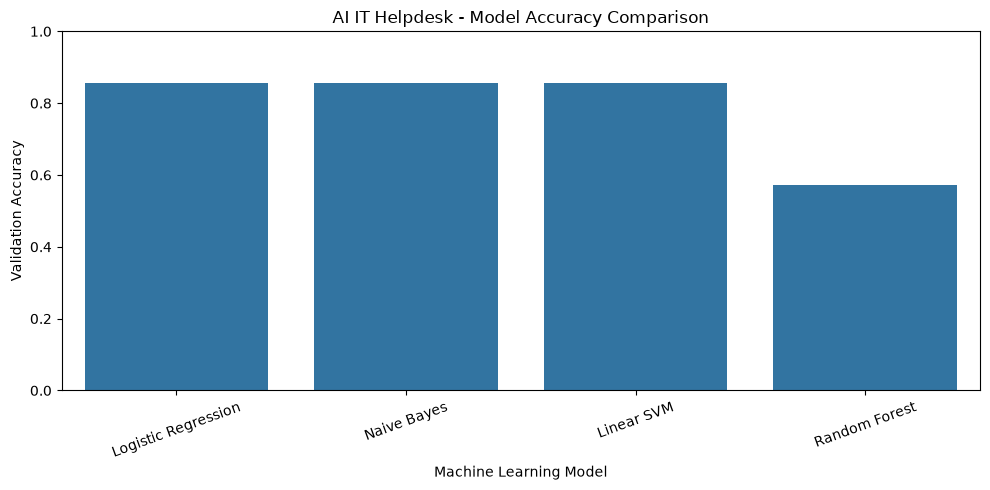

In [8]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("AI IT Helpdesk - Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Validation Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    RESULT_DIR / "model_accuracy_comparison.png",
    dpi=300
)

plt.show()


In [ ]:
# F1-score comparison

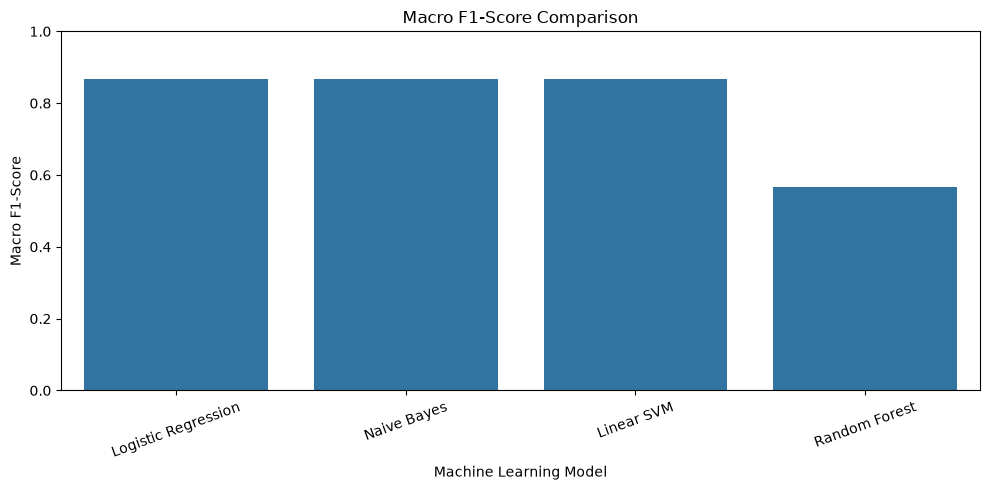

In [9]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Macro_F1"
)

plt.title("Macro F1-Score Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Macro F1-Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    RESULT_DIR / "model_f1_comparison.png",
    dpi=300
)

plt.show()


In [ ]:
# Select the best-performing model

In [10]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("=" * 45)
print("BEST MODEL SELECTED")
print("=" * 45)

print("Model:", best_model_name)
print("Validation Accuracy:",
      round(results_df.iloc[0]["Accuracy"], 4))

print("Validation Macro F1:",
      round(results_df.iloc[0]["Macro_F1"], 4))


BEST MODEL SELECTED
Model: Logistic Regression
Validation Accuracy: 0.8571
Validation Macro F1: 0.8667


In [ ]:
# Final model training

In [11]:
X_train_final = pd.concat(
    [X_train, X_val],
    ignore_index=True
)

y_train_final = pd.concat(
    [y_train, y_val],
    ignore_index=True
)

final_model = Pipeline([
    ("tfidf", TfidfVectorizer(**tfidf_settings)),
    ("classifier", models[best_model_name])
])

final_model.fit(X_train_final, y_train_final)

print("Final model trained successfully!")
print("Selected algorithm:", best_model_name)
print("Final training records:", len(X_train_final))


Final model trained successfully!
Selected algorithm: Logistic Regression
Final training records: 42


In [12]:
y_pred = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)

test_precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

print("=" * 50)
print("FINAL TEST PERFORMANCE")
print("=" * 50)

print("Selected Model:", best_model_name)
print("Accuracy:", round(test_accuracy, 4))
print("Precision:", round(test_precision, 4))
print("Recall:", round(test_recall, 4))
print("Macro F1-Score:", round(test_f1, 4))


FINAL TEST PERFORMANCE
Selected Model: Logistic Regression
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
Macro F1-Score: 1.0


In [ ]:
# Classification report

In [13]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=final_model.classes_,
        zero_division=0
    )
)

                    precision    recall  f1-score   support

Account & Password       1.00      1.00      1.00         2
     Network & VPN       1.00      1.00      1.00         1
           Printer       1.00      1.00      1.00         2
          Software       1.00      1.00      1.00         2
     System Health       1.00      1.00      1.00         1

          accuracy                           1.00         8
         macro avg       1.00      1.00      1.00         8
      weighted avg       1.00      1.00      1.00         8



In [ ]:
# Confusion matrix

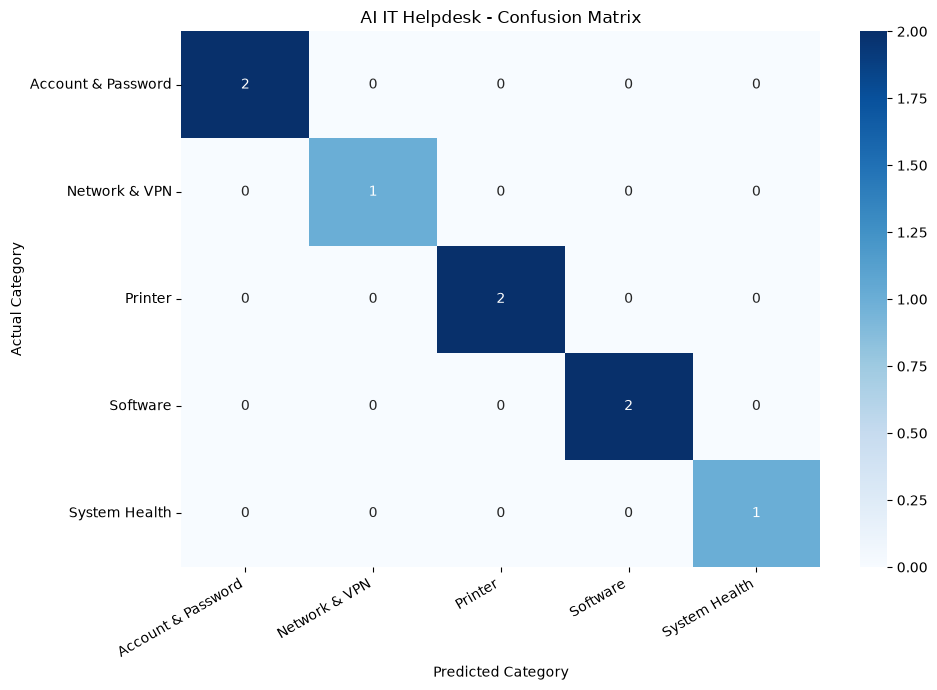

In [14]:

labels = final_model.classes_

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("AI IT Helpdesk - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    RESULT_DIR / "confusion_matrix.png",
    dpi=300
)

plt.show()


In [ ]:
# Save the trained AI model

In [15]:

MODEL_PATH = MODEL_DIR / "it_helpdesk_classifier.pkl"

joblib.dump(final_model, MODEL_PATH)

print("AI model saved successfully!")
print("Location:", MODEL_PATH)

AI model saved successfully!
Location: D:\AI_IT_HELPDESK\models\it_helpdesk_classifier.pkl


In [ ]:
# Test with new IT problems

In [16]:
# Load saved AI model
loaded_model = joblib.load(MODEL_PATH)

# New IT support queries
new_queries = [
    "My office internet connection is not working",
    "I cannot connect to the company VPN",
    "My printer is showing offline",
    "Windows application keeps crashing",
    "My computer is running very slowly",
    "I forgot my Windows password",
    "My laptop has very high RAM usage",
    "I cannot install Microsoft Office"
]

# Predict categories
predictions = loaded_model.predict(new_queries)

prediction_results = pd.DataFrame({
    "User Query": new_queries,
    "Predicted Category": predictions
})

display(prediction_results)

prediction_results.to_csv(
    RESULT_DIR / "sample_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Prediction testing completed!")

,User Query,Predicted Category
0,My office internet connection is not working,Network & VPN
1,I cannot connect to the company VPN,Network & VPN
2,My printer is showing offline,Printer
3,Windows application keeps crashing,Software
4,My computer is running very slowly,System Health
5,I forgot my Windows password,Account & Password
6,My laptop has very high RAM usage,System Health
7,I cannot install Microsoft Office,Software


Prediction testing completed!


In [ ]:
# Export evaluation results

In [17]:
final_results = pd.DataFrame([{
    "Selected_Model": best_model_name,
    "Test_Accuracy": test_accuracy,
    "Test_Precision_Macro": test_precision,
    "Test_Recall_Macro": test_recall,
    "Test_F1_Macro": test_f1,
    "Training_Records": len(X_train_final),
    "Testing_Records": len(X_test)
}])

final_results.to_csv(
    RESULT_DIR / "final_model_evaluation.csv",
    index=False
)

display(final_results)

print("Research evaluation results exported!")


,Selected_Model,Test_Accuracy,Test_Precision_Macro,Test_Recall_Macro,Test_F1_Macro,Training_Records,Testing_Records
0,Logistic Regression,1.0,1.0,1.0,1.0,42,8


Research evaluation results exported!


In [18]:
# Check duplicate queries across data splits

train_queries = set(
    train_df["user_query"].str.lower().str.strip()
)

val_queries = set(
    val_df["user_query"].str.lower().str.strip()
)

test_queries = set(
    test_df["user_query"].str.lower().str.strip()
)

print("Training / Validation overlap:",
      len(train_queries & val_queries))

print("Training / Testing overlap:",
      len(train_queries & test_queries))

print("Validation / Testing overlap:",
      len(val_queries & test_queries))


Training / Validation overlap: 0
Training / Testing overlap: 0
Validation / Testing overlap: 0
